Main simulation figure

In [3]:
# ============================================================
# Main IsoVita simulation study
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


# ============================================================
# 1. Reference simulation configuration
# ============================================================

BRANCHES = (
    "discrete",
    "continuous",
    "localized",
)

TRUTH_TYPES = (
    "discrete",
    "continuous",
    "localized",
)

SIGNAL_STRENGTHS = np.array(
    [0.05, 0.10, 0.20, 0.40, 0.80],
    dtype=float,
)

N_SAMPLES = 180
K = 4

# Two genes for every:
# trajectory truth × signal-strength combination.
GENES_PER_CELL = 2

# 3 truth types × 5 strengths × 2 genes = 30 alternatives.
N_ALTERNATIVE = (
    len(TRUTH_TYPES)
    * len(SIGNAL_STRENGTHS)
    * GENES_PER_CELL
)

# Reference mixed dataset is 50% null.
N_NULL = N_ALTERNATIVE
N_GENES = N_NULL + N_ALTERNATIVE

N_REPLICATES = 30

NOISE_SD = 0.30
NOISE_CORR = 0.10
BASELINE_SD = 0.22
LOADING_JITTER_SD = 0.05

ALPHA_FDR = 0.05

# Final manuscript setting.
N_PERMUTATIONS = 5000

BASE_SEED = 20260927


# Canonical truth locations.
TRUE_CHANGE_AGE = 35.0

TRUE_LOCALIZED_CENTER = 30.0
TRUE_LOCALIZED_WIDTH = 5.0
TRUE_LOCALIZED_WINDOW = "20-40"

CONTINUOUS_CENTER = 42.0
CONTINUOUS_SCALE = 16.0


# Reference dominant isoform direction.
REFERENCE_LOADINGS = np.array(
    [1.00, 0.82, -0.92, -0.75],
    dtype=float,
)


# ============================================================
# Check permutation resolution
# ============================================================

n_localized_hypotheses = (
    N_GENES
    * len(iso.WindowConfig().labels)
)

minimum_p = 1 / (
    N_PERMUTATIONS + 1
)

first_localized_bh_threshold = (
    ALPHA_FDR
    / n_localized_hypotheses
)

print(
    f"Genes per replicate: {N_GENES}"
)

print(
    "Localized hypotheses per replicate:",
    n_localized_hypotheses,
)

print(
    "Minimum permutation p-value:",
    f"{minimum_p:.6f}",
)

print(
    "First localized BH threshold:",
    f"{first_localized_bh_threshold:.6f}",
)

Genes per replicate: 60
Localized hypotheses per replicate: 240
Minimum permutation p-value: 0.000200
First localized BH threshold: 0.000208


In [4]:
# ============================================================
# 2. Scenario construction
# ============================================================

def jitter_reference_loadings(
    rng,
):
    """
    Create a slightly different dominant compositional
    direction for each simulated alternative gene.

    The direction is centered because a common shift across
    all transcript log-abundances disappears under softmax.
    """
    loading = (
        REFERENCE_LOADINGS
        + rng.normal(
            0.0,
            LOADING_JITTER_SD,
            size=K,
        )
    )

    loading = (
        loading
        - loading.mean()
    )

    loading = (
        loading
        / np.max(np.abs(loading))
    )

    return tuple(
        loading.tolist()
    )


def make_main_simulation_scenarios(
    replicate,
):
    """
    Build one mixed simulation dataset containing:

      - age-null genes
      - discrete alternatives
      - continuous alternatives
      - localized alternatives

    Alternatives occur at each configured signal strength.

    Returns
    -------
    scenarios
        Tuple of IsoformScenario objects.

    truth
        Gene-level truth table.
    """

    rng = np.random.default_rng(
        BASE_SEED
        + 100_000 * replicate
        + 11
    )

    scenarios = []
    truth_rows = []

    # --------------------------------------------------------
    # Null genes
    # --------------------------------------------------------

    for i in range(N_NULL):

        gene_id = (
            f"R{replicate:03d}_"
            f"NULL_{i + 1:03d}"
        )

        baselines = tuple(
            rng.normal(
                0.0,
                BASELINE_SD,
                size=K,
            ).tolist()
        )

        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=baselines,
                components=(),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
                notes=(
                    "No age-dependent latent component."
                ),
            )
        )

        truth_rows.append({
            "gene_id": gene_id,
            "truth_type": "null",
            "signal_strength": 0.0,
            "true_change_age": np.nan,
            "true_window": None,
        })

    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for truth_type in TRUTH_TYPES:

        for strength_index, strength in enumerate(
            SIGNAL_STRENGTHS
        ):

            for gene_index in range(
                GENES_PER_CELL
            ):

                gene_id = (
                    f"R{replicate:03d}_"
                    f"{truth_type.upper()}_"
                    f"S{strength_index + 1}_"
                    f"G{gene_index + 1}"
                )

                baselines = tuple(
                    rng.normal(
                        0.0,
                        BASELINE_SD,
                        size=K,
                    ).tolist()
                )

                loadings = (
                    jitter_reference_loadings(
                        rng
                    )
                )

                if truth_type == "discrete":

                    component = (
                        isim.TemporalComponent(
                            kind="step",
                            loadings=loadings,
                            amplitude=float(
                                strength
                            ),
                            params={
                                "change_age":
                                    TRUE_CHANGE_AGE,
                            },
                        )
                    )

                    true_change_age = (
                        TRUE_CHANGE_AGE
                    )

                    true_window = None

                elif truth_type == "continuous":

                    component = (
                        isim.TemporalComponent(
                            kind="sigmoid",
                            loadings=loadings,
                            amplitude=float(
                                strength
                            ),
                            params={
                                "center":
                                    CONTINUOUS_CENTER,

                                "scale":
                                    CONTINUOUS_SCALE,
                            },
                        )
                    )

                    true_change_age = np.nan
                    true_window = None

                elif truth_type == "localized":

                    component = (
                        isim.TemporalComponent(
                            kind="localized",
                            loadings=loadings,
                            amplitude=float(
                                strength
                            ),
                            params={
                                "center":
                                    TRUE_LOCALIZED_CENTER,

                                "width":
                                    TRUE_LOCALIZED_WIDTH,
                            },
                        )
                    )

                    true_change_age = np.nan
                    true_window = (
                        TRUE_LOCALIZED_WINDOW
                    )

                else:
                    raise ValueError(
                        truth_type
                    )

                scenarios.append(
                    isim.IsoformScenario(
                        gene_id=gene_id,
                        label=(
                            f"{truth_type.capitalize()} "
                            f"(amplitude={strength:g})"
                        ),
                        baselines=baselines,
                        components=(
                            component,
                        ),
                        noise_sd=NOISE_SD,
                        noise_corr=NOISE_CORR,
                    )
                )

                truth_rows.append({
                    "gene_id": gene_id,
                    "truth_type": truth_type,
                    "signal_strength":
                        float(strength),

                    "true_change_age":
                        true_change_age,

                    "true_window":
                        true_window,
                })

    return (
        tuple(scenarios),
        pd.DataFrame(truth_rows),
    )

In [5]:
# ============================================================
# 3. Run one complete simulation replicate
# ============================================================

def run_main_simulation_replicate(
    replicate,
):
    """
    Simulate one mixed dataset and run the complete
    selection-aware IsoVita inference procedure.
    """

    # --------------------------------------------------------
    # Simulate
    # --------------------------------------------------------

    scenarios, truth = (
        make_main_simulation_scenarios(
            replicate
        )
    )

    sim_seed = (
        BASE_SEED
        + 100_000 * replicate
        + 21
    )

    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            n_samples=N_SAMPLES,
            age_min=0,
            age_max=85,
            age_design="uniform",
            seed=sim_seed,
            sample_prefix=(
                f"R{replicate:03d}_S"
            ),
        )
    )

    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )

    # --------------------------------------------------------
    # Observed one-feature-per-gene condensation
    # --------------------------------------------------------

    (
        balance_summary,
        balance_loadings,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=iso.BalanceConfig(),
    )

    failed = (
        balance_summary.loc[
            ~balance_summary[
                "status"
            ].eq("ok")
        ]
    )

    if not failed.empty:
        raise RuntimeError(
            "Feature condensation failed:\n"
            + failed.to_string()
        )

    # --------------------------------------------------------
    # Selection-aware inference
    #
    # One call for all three branches. Each permutation
    # relearns the age-informed balance once, then shares
    # that permuted feature across branches.
    # --------------------------------------------------------

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            expression_df=(
                sim_data.expression
            ),
            global_metrics=(
                sim_data.global_metrics
            ),
            sample_cols=sample_cols,
            metadata=sim_data.metadata,
            branches=BRANCHES,
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            balance_config=(
                iso.BalanceConfig()
            ),
            discrete_config=(
                iso.DiscreteConfig(
                    alpha_fdr=ALPHA_FDR,
                )
            ),
            feature_config=(
                iso.FeatureTestConfig(
                    alpha_fdr=ALPHA_FDR,
                )
            ),
            windows=(
                iso.WindowConfig()
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        N_PERMUTATIONS
                    ),
                    random_seed=(
                        BASE_SEED
                        + 100_000 * replicate
                        + 31
                    ),
                )
            ),
        )
    )

    # --------------------------------------------------------
    # Merge branch evidence at the gene level
    # --------------------------------------------------------

    gene_summary = (
        iso.summarize_gene_trajectories(
            balance_summary,
            branch_results[
                "discrete"
            ],
            branch_results[
                "continuous"
            ],
            branch_results[
                "localized"
            ],
            branches=BRANCHES,
        )
    )

    keep_cols = [
        "gene_id",

        "discrete_fdr_significant",
        "continuous_fdr_significant",
        "localized_fdr_significant",

        "discrete_change_age",

        "best_window",
        "significant_windows",

        "pc1_explained_variance_ratio",
        "cosine_similarity",
    ]

    calls = (
        truth.merge(
            gene_summary[
                keep_cols
            ],
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )

    if calls[
        [
            "discrete_fdr_significant",
            "continuous_fdr_significant",
            "localized_fdr_significant",
        ]
    ].isna().any().any():

        raise RuntimeError(
            "Some simulated genes are missing "
            "from the IsoVita result."
        )

    calls = calls.rename(
        columns={
            "discrete_fdr_significant":
                "discrete_called",

            "continuous_fdr_significant":
                "continuous_called",

            "localized_fdr_significant":
                "localized_called",
        }
    )

    for column in (
        "discrete_called",
        "continuous_called",
        "localized_called",
    ):
        calls[column] = (
            calls[column]
            .astype(bool)
        )

    calls[
        "union_called"
    ] = (
        calls[
            [
                "discrete_called",
                "continuous_called",
                "localized_called",
            ]
        ]
        .any(axis=1)
    )

    calls[
        "replicate"
    ] = replicate

    return calls

In [6]:
# ============================================================
# 4. Replicate-level operating characteristics
# ============================================================

CALL_COLUMNS = {
    "discrete": "discrete_called",
    "continuous": "continuous_called",
    "localized": "localized_called",
    "union": "union_called",
}


def summarize_fdr(
    calls,
):
    """
    Gene-level empirical false-discovery proportion.

    A discovery is false only when the underlying gene is
    completely age-null.

    The union is reported descriptively; it is not a
    separately FDR-calibrated testing family.
    """

    replicate = int(
        calls["replicate"].iloc[0]
    )

    rows = []

    for detector, call_col in (
        CALL_COLUMNS.items()
    ):

        called = (
            calls[call_col]
            .astype(bool)
        )

        n_discoveries = int(
            called.sum()
        )

        n_false = int(
            (
                called
                & calls[
                    "truth_type"
                ].eq("null")
            ).sum()
        )

        fdp = (
            n_false
            / max(
                n_discoveries,
                1,
            )
        )

        rows.append({
            "replicate": replicate,
            "detector": detector,
            "n_discoveries":
                n_discoveries,

            "n_false_discoveries":
                n_false,

            "fdp":
                float(fdp),
        })

    return pd.DataFrame(rows)


def summarize_power(
    calls,
):
    """
    Detection probability for each truth type and
    signal-strength combination.

    Each detector is evaluated against every alternative
    truth because branches are intentionally overlapping.
    """

    replicate = int(
        calls["replicate"].iloc[0]
    )

    rows = []

    alternatives = (
        calls.loc[
            ~calls[
                "truth_type"
            ].eq("null")
        ]
    )

    for truth_type in TRUTH_TYPES:

        for strength in SIGNAL_STRENGTHS:

            sub = alternatives.loc[
                alternatives[
                    "truth_type"
                ].eq(truth_type)
                & np.isclose(
                    alternatives[
                        "signal_strength"
                    ],
                    strength,
                )
            ]

            if sub.empty:
                raise RuntimeError(
                    "Missing simulation cell: "
                    f"{truth_type}, {strength}"
                )

            for detector, call_col in (
                CALL_COLUMNS.items()
            ):

                rows.append({
                    "replicate":
                        replicate,

                    "truth_type":
                        truth_type,

                    "signal_strength":
                        float(strength),

                    "detector":
                        detector,

                    "power":
                        float(
                            sub[
                                call_col
                            ].mean()
                        ),
                })

    return pd.DataFrame(rows)

In [7]:
# ============================================================
# 5. Run complete main simulation study
# ============================================================

all_calls = []
all_fdr = []
all_power = []


for replicate in range(
    N_REPLICATES
):

    print(
        f"Main simulation replicate "
        f"{replicate + 1}/{N_REPLICATES}",
        flush=True,
    )

    calls = (
        run_main_simulation_replicate(
            replicate
        )
    )

    all_calls.append(
        calls
    )

    all_fdr.append(
        summarize_fdr(
            calls
        )
    )

    all_power.append(
        summarize_power(
            calls
        )
    )


main_calls = pd.concat(
    all_calls,
    ignore_index=True,
)

main_fdr_by_replicate = pd.concat(
    all_fdr,
    ignore_index=True,
)

main_power_by_replicate = pd.concat(
    all_power,
    ignore_index=True,
)


print(
    main_calls.shape,
    main_fdr_by_replicate.shape,
    main_power_by_replicate.shape,
)

Main simulation replicate 1/30
Main simulation replicate 2/30
Main simulation replicate 3/30
Main simulation replicate 4/30
Main simulation replicate 5/30
Main simulation replicate 6/30
Main simulation replicate 7/30
Main simulation replicate 8/30
Main simulation replicate 9/30
Main simulation replicate 10/30
Main simulation replicate 11/30
Main simulation replicate 12/30
Main simulation replicate 13/30
Main simulation replicate 14/30
Main simulation replicate 15/30
Main simulation replicate 16/30
Main simulation replicate 17/30
Main simulation replicate 18/30
Main simulation replicate 19/30
Main simulation replicate 20/30
Main simulation replicate 21/30
Main simulation replicate 22/30
Main simulation replicate 23/30
Main simulation replicate 24/30
Main simulation replicate 25/30
Main simulation replicate 26/30
Main simulation replicate 27/30
Main simulation replicate 28/30
Main simulation replicate 29/30
Main simulation replicate 30/30
(1800, 15) (120, 5) (1800, 5)


In [8]:
# ============================================================
# 6. Save expensive simulation outputs
# ============================================================

RESULT_DIR = Path(
    "results/main_simulation"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

main_calls.to_csv(
    RESULT_DIR
    / "gene_level_calls.csv",
    index=False,
)

main_fdr_by_replicate.to_csv(
    RESULT_DIR
    / "fdr_by_replicate.csv",
    index=False,
)

main_power_by_replicate.to_csv(
    RESULT_DIR
    / "power_by_replicate.csv",
    index=False,
)

In [9]:
# ============================================================
# 7. Aggregate operating characteristics
# ============================================================

def mean_ci(
    values,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    mean = float(
        np.mean(values)
    )

    if n <= 1:
        return pd.Series({
            "mean": mean,
            "ci_low": np.nan,
            "ci_high": np.nan,
        })

    se = (
        np.std(
            values,
            ddof=1,
        )
        / np.sqrt(n)
    )

    return pd.Series({
        "mean": mean,
        "ci_low": max(
            0.0,
            mean - 1.96 * se,
        ),
        "ci_high": min(
            1.0,
            mean + 1.96 * se,
        ),
    })


# ------------------------------------------------------------
# FDR
# ------------------------------------------------------------

fdr_summary = (
    main_fdr_by_replicate
    .groupby(
        "detector"
    )[
        "fdp"
    ]
    .apply(mean_ci)
    .unstack()
    .reset_index()
)


# ------------------------------------------------------------
# Power
# ------------------------------------------------------------

power_summary = (
    main_power_by_replicate
    .groupby(
        [
            "truth_type",
            "signal_strength",
            "detector",
        ]
    )[
        "power"
    ]
    .apply(mean_ci)
    .unstack()
    .reset_index()
)


# ------------------------------------------------------------
# Discrete changepoint recovery
#
# Importantly, this is NOT conditioned on significance.
# Every tested discrete-truth gene contributes.
# ------------------------------------------------------------

discrete_location = (
    main_calls.loc[
        main_calls[
            "truth_type"
        ].eq("discrete")
    ]
    .copy()
)

discrete_location[
    "absolute_change_age_error"
] = np.abs(
    discrete_location[
        "discrete_change_age"
    ]
    - discrete_location[
        "true_change_age"
    ]
)

discrete_location_by_rep = (
    discrete_location
    .groupby(
        [
            "replicate",
            "signal_strength",
        ],
        as_index=False,
    )
    .agg(
        median_absolute_error=(
            "absolute_change_age_error",
            "median",
        )
    )
)

discrete_location_summary = (
    discrete_location_by_rep
    .groupby(
        "signal_strength",
        as_index=False,
    )
    .agg(
        median_error=(
            "median_absolute_error",
            "median",
        ),

        q25=(
            "median_absolute_error",
            lambda x:
                np.quantile(
                    x,
                    0.25,
                ),
        ),

        q75=(
            "median_absolute_error",
            lambda x:
                np.quantile(
                    x,
                    0.75,
                ),
        ),
    )
)


# ------------------------------------------------------------
# Localized best-window recovery
#
# Again, this is unconditional on statistical significance:
# did the 20-40 window contain the strongest localized evidence?
# ------------------------------------------------------------

localized_location = (
    main_calls.loc[
        main_calls[
            "truth_type"
        ].eq("localized")
    ]
    .copy()
)

localized_location[
    "correct_best_window"
] = (
    localized_location[
        "best_window"
    ]
    == localized_location[
        "true_window"
    ]
)

localized_location_by_rep = (
    localized_location
    .groupby(
        [
            "replicate",
            "signal_strength",
        ],
        as_index=False,
    )
    .agg(
        correct_window_rate=(
            "correct_best_window",
            "mean",
        )
    )
)

localized_location_summary = (
    localized_location_by_rep
    .groupby(
        "signal_strength"
    )[
        "correct_window_rate"
    ]
    .apply(mean_ci)
    .unstack()
    .reset_index()
)


display(fdr_summary)
display(power_summary)
display(discrete_location_summary)
display(localized_location_summary)

,detector,mean,ci_low,ci_high
0,continuous,0.019910,0.011161,0.028659
1,discrete,0.026306,0.013907,0.038706
2,localized,0.027070,0.013167,0.040972
3,union,0.051127,0.033960,0.068294


,truth_type,signal_strength,detector,mean,ci_low,ci_high
0,continuous,0.05,continuous,0.383333,0.261861,0.504806
1,continuous,0.05,discrete,0.400000,0.272180,0.527820
2,continuous,0.05,localized,0.016667,0.000000,0.049333
3,continuous,0.05,union,0.450000,0.314223,0.585777
4,continuous,0.10,continuous,1.000000,1.000000,1.000000
5,continuous,0.10,discrete,1.000000,1.000000,1.000000
6,continuous,0.10,localized,0.016667,0.000000,0.049333
7,continuous,0.10,union,1.000000,1.000000,1.000000
8,continuous,0.20,continuous,1.000000,1.000000,1.000000
9,continuous,0.20,discrete,1.000000,1.000000,1.000000


,signal_strength,median_error,q25,q75
0,0.05,5.665581,2.378082,9.145975
1,0.10,1.132396,0.783474,1.504273
2,0.20,0.308781,0.146021,0.574433
3,0.40,0.146904,0.094267,0.280211
4,0.80,0.150312,0.094267,0.280211


,signal_strength,mean,ci_low,ci_high
0,0.05,0.283333,0.161861,0.404806
1,0.10,0.400000,0.281130,0.518870
2,0.20,0.700000,0.579287,0.820713
3,0.40,1.000000,1.000000,1.000000
4,0.80,1.000000,1.000000,1.000000


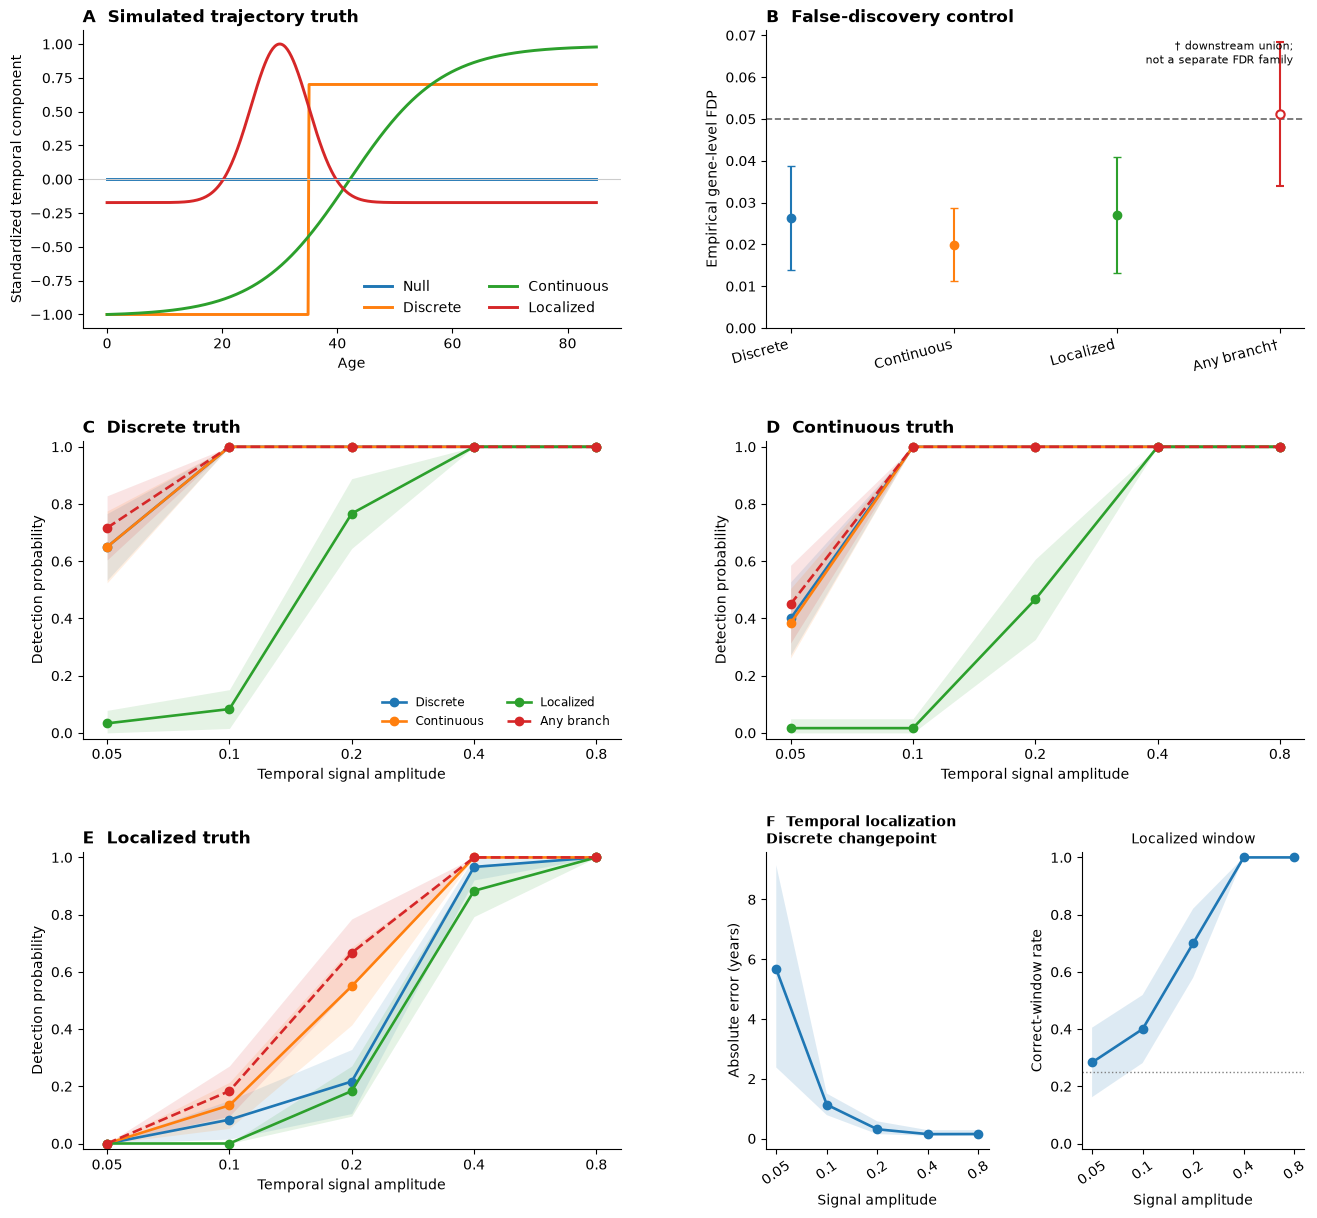

In [10]:
# ============================================================
# 8. Assemble main simulation figure
# ============================================================

fig = plt.figure(
    figsize=(13.5, 12.5)
)

gs = fig.add_gridspec(
    3,
    2,
    left=0.08,
    right=0.985,
    bottom=0.07,
    top=0.965,
    wspace=0.27,
    hspace=0.38,
)


ax_a = fig.add_subplot(
    gs[0, 0]
)

ax_b = fig.add_subplot(
    gs[0, 1]
)

ax_c = fig.add_subplot(
    gs[1, 0]
)

ax_d = fig.add_subplot(
    gs[1, 1]
)

ax_e = fig.add_subplot(
    gs[2, 0]
)

gs_f = gs[
    2,
    1,
].subgridspec(
    1,
    2,
    wspace=0.42,
)

ax_f1 = fig.add_subplot(
    gs_f[0, 0]
)

ax_f2 = fig.add_subplot(
    gs_f[0, 1]
)


# ============================================================
# A. Simulation truth
# ============================================================

age_grid = np.linspace(
    0,
    85,
    500,
)

truth_curves = {
    "Null":
        np.zeros_like(
            age_grid
        ),

    "Discrete":
        isim.temporal_basis(
            age_grid,
            "step",
            {
                "change_age":
                    TRUE_CHANGE_AGE
            },
        ),

    "Continuous":
        isim.temporal_basis(
            age_grid,
            "sigmoid",
            {
                "center":
                    CONTINUOUS_CENTER,

                "scale":
                    CONTINUOUS_SCALE,
            },
        ),

    "Localized":
        isim.temporal_basis(
            age_grid,
            "localized",
            {
                "center":
                    TRUE_LOCALIZED_CENTER,

                "width":
                    TRUE_LOCALIZED_WIDTH,
            },
        ),
}


for label, curve in (
    truth_curves.items()
):

    ax_a.plot(
        age_grid,
        curve,
        lw=2.1,
        label=label,
    )


ax_a.axhline(
    0,
    lw=0.8,
    color="0.8",
)

ax_a.set_xlabel(
    "Age"
)

ax_a.set_ylabel(
    "Standardized temporal component"
)

ax_a.set_title(
    "A  Simulated trajectory truth",
    loc="left",
    fontweight="bold",
)

ax_a.legend(
    frameon=False,
    ncol=2,
)


# ============================================================
# B. Empirical gene-level FDP/FDR
# ============================================================

detector_order = [
    "discrete",
    "continuous",
    "localized",
    "union",
]

detector_labels = [
    "Discrete",
    "Continuous",
    "Localized",
    "Any branch†",
]

fdr_plot = (
    fdr_summary
    .set_index(
        "detector"
    )
    .loc[
        detector_order
    ]
    .reset_index()
)

x = np.arange(
    len(fdr_plot)
)


for i, row in (
    fdr_plot.iterrows()
):

    yerr = np.array([
        [
            row["mean"]
            - row["ci_low"]
        ],
        [
            row["ci_high"]
            - row["mean"]
        ],
    ])

    if row[
        "detector"
    ] == "union":

        ax_b.errorbar(
            i,
            row["mean"],
            yerr=yerr,
            fmt="o",
            markerfacecolor="white",
            markeredgewidth=1.5,
            capsize=3,
        )

    else:

        ax_b.errorbar(
            i,
            row["mean"],
            yerr=yerr,
            fmt="o",
            capsize=3,
        )


ax_b.axhline(
    ALPHA_FDR,
    ls="--",
    lw=1.2,
    color="0.4",
)

ax_b.set_xticks(
    x
)

ax_b.set_xticklabels(
    detector_labels,
    rotation=15,
    ha="right",
)

ax_b.set_ylabel(
    "Empirical gene-level FDP"
)

ax_b.set_ylim(
    bottom=0
)

ax_b.set_title(
    "B  False-discovery control",
    loc="left",
    fontweight="bold",
)

ax_b.text(
    0.98,
    0.97,
    "† downstream union;\nnot a separate FDR family",
    transform=ax_b.transAxes,
    ha="right",
    va="top",
    fontsize=8,
)


# ============================================================
# C-E. Power curves
# ============================================================

POWER_PANELS = [
    (
        ax_c,
        "discrete",
        "C  Discrete truth",
    ),
    (
        ax_d,
        "continuous",
        "D  Continuous truth",
    ),
    (
        ax_e,
        "localized",
        "E  Localized truth",
    ),
]

power_detector_order = [
    "discrete",
    "continuous",
    "localized",
    "union",
]

power_detector_labels = {
    "discrete":
        "Discrete",

    "continuous":
        "Continuous",

    "localized":
        "Localized",

    "union":
        "Any branch",
}


for (
    ax,
    truth_type,
    title,
) in POWER_PANELS:

    sub = (
        power_summary.loc[
            power_summary[
                "truth_type"
            ].eq(truth_type)
        ]
    )

    for detector in (
        power_detector_order
    ):

        curve = (
            sub.loc[
                sub[
                    "detector"
                ].eq(detector)
            ]
            .sort_values(
                "signal_strength"
            )
        )

        linestyle = (
            "--"
            if detector == "union"
            else "-"
        )

        line, = ax.plot(
            curve[
                "signal_strength"
            ],
            curve[
                "mean"
            ],
            marker="o",
            lw=1.9,
            ls=linestyle,
            label=(
                power_detector_labels[
                    detector
                ]
            ),
        )

        ax.fill_between(
            curve[
                "signal_strength"
            ],
            curve[
                "ci_low"
            ],
            curve[
                "ci_high"
            ],
            alpha=0.12,
            color=line.get_color(),
            linewidth=0,
        )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        SIGNAL_STRENGTHS
    )

    ax.set_xticklabels(
        [
            f"{x:g}"
            for x in SIGNAL_STRENGTHS
        ]
    )

    ax.set_ylim(
        -0.02,
        1.02,
    )

    ax.set_xlabel(
        "Temporal signal amplitude"
    )

    ax.set_ylabel(
        "Detection probability"
    )

    ax.set_title(
        title,
        loc="left",
        fontweight="bold",
    )


ax_c.legend(
    frameon=False,
    fontsize=8.5,
    ncol=2,
    loc="lower right",
)


# ============================================================
# F1. Discrete changepoint localization
# ============================================================

ax_f1.plot(
    discrete_location_summary[
        "signal_strength"
    ],
    discrete_location_summary[
        "median_error"
    ],
    marker="o",
    lw=1.9,
)

ax_f1.fill_between(
    discrete_location_summary[
        "signal_strength"
    ],
    discrete_location_summary[
        "q25"
    ],
    discrete_location_summary[
        "q75"
    ],
    alpha=0.15,
)

ax_f1.set_xscale(
    "log",
    base=2,
)

ax_f1.set_xticks(
    SIGNAL_STRENGTHS
)

ax_f1.set_xticklabels(
    [
        f"{x:g}"
        for x in SIGNAL_STRENGTHS
    ],
    rotation=35,
)

ax_f1.set_xlabel(
    "Signal amplitude"
)

ax_f1.set_ylabel(
    "Absolute error (years)"
)

ax_f1.set_title(
    "F  Temporal localization\nDiscrete changepoint",
    loc="left",
    fontweight="bold",
    fontsize=10,
)


# ============================================================
# F2. Localized-window recovery
# ============================================================

ax_f2.plot(
    localized_location_summary[
        "signal_strength"
    ],
    localized_location_summary[
        "mean"
    ],
    marker="o",
    lw=1.9,
)

ax_f2.fill_between(
    localized_location_summary[
        "signal_strength"
    ],
    localized_location_summary[
        "ci_low"
    ],
    localized_location_summary[
        "ci_high"
    ],
    alpha=0.15,
)

# Four default windows -> random-choice reference = 0.25.
ax_f2.axhline(
    1 / len(
        iso.WindowConfig().labels
    ),
    ls=":",
    lw=1.0,
    color="0.5",
)

ax_f2.set_xscale(
    "log",
    base=2,
)

ax_f2.set_xticks(
    SIGNAL_STRENGTHS
)

ax_f2.set_xticklabels(
    [
        f"{x:g}"
        for x in SIGNAL_STRENGTHS
    ],
    rotation=35,
)

ax_f2.set_ylim(
    -0.02,
    1.02,
)

ax_f2.set_xlabel(
    "Signal amplitude"
)

ax_f2.set_ylabel(
    "Correct-window rate"
)

ax_f2.set_title(
    "Localized window",
    fontsize=10,
)


# ============================================================
# Shared cosmetics
# ============================================================

for ax in (
    ax_a,
    ax_b,
    ax_c,
    ax_d,
    ax_e,
    ax_f1,
    ax_f2,
):

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


plt.show()

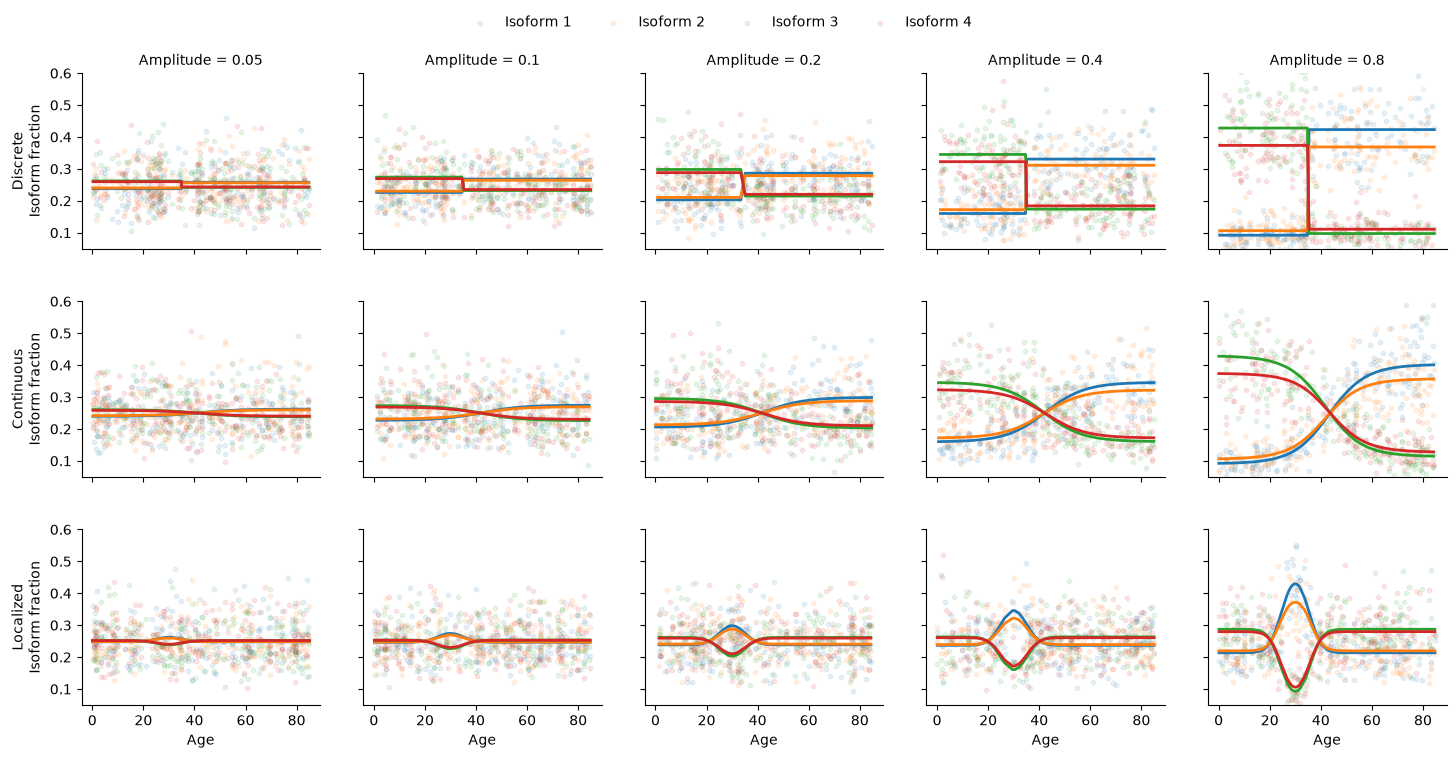

In [15]:
# ============================================================
# Supplementary figure — observed isoform fractions across
# signal amplitudes, with true underlying fraction trajectories
# ============================================================

trajectory_specs = {
    "Discrete": (
        "step",
        {
            "change_age":
                TRUE_CHANGE_AGE,
        },
    ),

    "Continuous": (
        "sigmoid",
        {
            "center":
                CONTINUOUS_CENTER,
            "scale":
                CONTINUOUS_SCALE,
        },
    ),

    "Localized": (
        "localized",
        {
            "center":
                TRUE_LOCALIZED_CENTER,
            "width":
                TRUE_LOCALIZED_WIDTH,
        },
    ),
}


# ------------------------------------------------------------
# Build one representative simulated gene for each condition
# ------------------------------------------------------------

visualization_rows = []

for row, (
    trajectory_name,
    (
        kind,
        params,
    ),
) in enumerate(
    trajectory_specs.items()
):

    for col, amplitude in enumerate(
        SIGNAL_STRENGTHS
    ):

        gene_id = (
            f"VIS_{trajectory_name.upper()}_"
            f"{amplitude:g}"
        )

        scenario = (
            isim.IsoformScenario(
                gene_id=gene_id,
                label=trajectory_name,
                baselines=tuple(
                    np.zeros(K)
                ),
                components=(
                    isim.TemporalComponent(
                        kind=kind,
                        loadings=tuple(
                            REFERENCE_LOADINGS
                        ),
                        amplitude=float(
                            amplitude
                        ),
                        params=params,
                    ),
                ),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
            )
        )

        sim = (
            isim.simulate_isovita_dataset(
                (
                    scenario,
                ),
                n_samples=N_SAMPLES,
                age_min=0,
                age_max=85,
                age_design="uniform",
                seed=(
                    BASE_SEED
                    + 10_000
                    + 100 * row
                    + col
                ),
            )
        )

        visualization_rows.append(
            {
                "trajectory_name":
                    trajectory_name,

                "amplitude":
                    float(amplitude),

                "gene_id":
                    gene_id,

                "sim":
                    sim,
            }
        )


# ============================================================
# Assemble 3 × 5 visualization
# ============================================================

fig, axes = plt.subplots(
    3,
    len(SIGNAL_STRENGTHS),
    figsize=(15, 7.8),
    sharex=True,
    sharey=True,
)

fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.09,
    top=0.90,
    wspace=0.18,
    hspace=0.30,
)


for item in visualization_rows:

    trajectory_name = (
        item["trajectory_name"]
    )

    amplitude = (
        item["amplitude"]
    )

    row = list(
        trajectory_specs.keys()
    ).index(
        trajectory_name
    )

    col = int(
        np.where(
            np.isclose(
                SIGNAL_STRENGTHS,
                amplitude,
            )
        )[0][0]
    )

    ax = axes[
        row,
        col,
    ]

    gene = (
        item["gene_id"]
    )

    sim = (
        item["sim"]
    )

    frac = (
        sim.fractions
        .loc[
            lambda x:
                x["gene_id"].eq(
                    gene
                )
        ]
        .copy()
    )

    transcript_order = (
        frac[
            "transcript_id"
        ]
        .drop_duplicates()
        .tolist()
    )

    for isoform_index, tx in enumerate(
        transcript_order
    ):

        sub = (
            frac.loc[
                frac[
                    "transcript_id"
                ].eq(tx)
            ]
            .sort_values(
                "age"
            )
        )

        color = f"C{isoform_index}"

        # Observed noisy fractions
        ax.scatter(
            sub["age"],
            sub["fraction"],
            s=10,
            alpha=0.10,
            color=color,
            label=(
                f"Isoform "
                f"{isoform_index + 1}"
            ),
        )

        # True underlying fraction trajectory
        ax.plot(
            sub["age"],
            sub["true_fraction"],
            color=color,
            lw=2.0,
        )

    if row == 0:
        ax.set_title(
            f"Amplitude = {amplitude:g}",
            fontsize=10,
        )

    if col == 0:
        ax.set_ylabel(
            f"{trajectory_name}\n"
            "Isoform fraction"
        )

    if row == (
        len(
            trajectory_specs
        ) - 1
    ):
        ax.set_xlabel(
            "Age"
        )

    # Reduced common y-axis to make the fraction patterns
    # easier to visually compare across panels.
    ax.set_ylim(
        0.05,
        0.60,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles, labels = (
    axes[
        0,
        0,
    ].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.99,
    ),
    ncol=4,
    frameon=False,
)


plt.show()